In [11]:
!pip uninstall -y -q torchao
!pip install -q sentencepiece

In [12]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"       # one GPU -> real batch size as in the paper
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import subprocess, time, gc, shutil, inspect, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_fscore_support
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments,
                          EarlyStoppingCallback, DataCollatorWithPadding, set_seed)
from peft import LoraConfig, TaskType, get_peft_model
warnings.filterwarnings("ignore")

REPO = "/kaggle/working/senti-matrix"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/ELTE-DSED/senti-matrix.git", REPO], check=True)
OUT = "/kaggle/working/outputs"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42]        # [42, 43, 44] gives mean ± std like the paper (3x longer)
DATASETS = ["sst2", "emotion", "ecom5", "absa"]   # also available: "twitter", "imdb" (both long)
HAS_GPU = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "NONE - turn on a GPU in Settings")

GPU: Tesla T4


In [13]:
def paper(acc, prec, rec, f1, sim, conf, ece, brier, params, secs, gpu):
    keys = ["Accuracy", "Precision", "Recall", "F1", "Similarity", "Confidence", "ECE", "Brier"]
    d = dict(zip(keys, [acc, prec, rec, f1, sim, conf, ece, brier]))
    d.update(Params=params, Time=secs, GPU=gpu)
    return d

LORA_DEFAULTS = dict(warmup=0.1, patience=3)   # not listed in Table 3b; SST-2 recipe from the authors' code

CONFIG = {
 "sst2": dict(
    title="SST-2 (2-class)", file="SST-2 (2 Classes).csv", n_paper=9613,
    classes=[0, 1], names=["Negative", "Positive"], max_len=512, avg="macro",
    models=[
      dict(tag="DistilBERT", name="distilbert-base-uncased", targets=["q_lin", "v_lin", "out_lin"],
           r=6, alpha=12, dropout=0.20, lr=3e-4, bs=(8, 16), epochs=10, wd=0.05,
           paper=paper((89.02,.95),(90.53,2.70),(88.13,3.96),(89.22,1.18),(90.76,.71),(92.06,2.74),(3.86,1.71),(.17,.01),"758K",195,0.46)),
      dict(tag="RoBERTa", name="roberta-base", targets=["query", "value", "output.dense"],
           r=6, alpha=12, dropout=0.20, lr=3e-4, bs=(8, 16), epochs=10, wd=0.05,
           paper=paper((93.28,.91),(93.42,1.60),(93.64,2.14),(93.51,.91),(94.28,.61),(95.67,2.68),(3.15,1.04),(.11,.01),"1.20M",392,0.92))]),
 "emotion": dict(
    title="CARER Emotion (6-class)", file="Emotion Dataset (Small).csv", n_paper=75000,
    classes=["sadness", "joy", "love", "anger", "fear", "surprise"], max_len=512, avg="macro",
    models=[
      dict(tag="DistilBERT", name="distilbert-base-uncased", targets=["q_lin", "v_lin"],
           r=8, alpha=16, dropout=0.10, lr=3e-4, bs=(32, 64), epochs=5, wd=0.01, warmup=0.03, patience=1,
           paper=paper((93.22,.03),(89.85,.03),(90.60,.03),(90.20,.03),(92.45,.01),(94.70,.03),(1.73,.12),(.083,0),"742.66K",364.3,1.15))]),
 "ecom5": dict(
    title="Amazon E-Commerce (5-class)", file="E-Commerce Reviews (5 Classes).csv", n_paper=22641,
    classes=["Very Negative", "Negative", "Neutral", "Positive", "Very Positive"], max_len=256, avg="macro",
    models=[
      dict(tag="mBERT", name="bert-base-multilingual-uncased", targets=["query", "value"],
           r=8, alpha=16, dropout=0.05, lr=3e-4, bs=(8, 16), epochs=3, wd=0.01,
           paper=paper((67.63,.26),(53.88,2.34),(46.05,1.07),(47.37,1.48),(74.06,.03),(71.03,.37),(3.67,.35),(.43,0),"298.76K",412.93,1.22))]),
 "absa": dict(
    title="SemEval-2014 ABSA (Laptop+Restaurant, 3-class)", file="Laptop + Restaurant - ABSA.csv", n_paper=5914,
    classes=["Negative", "Neutral", "Positive"], max_len=512,
    avg="weighted",        # the paper's ABSA Recall equals Accuracy, which weighted averaging gives
    use_aspect=False,      # authors' notebook feeds only the sentence; True = (sentence, aspect term) pairs
    models=[
      dict(tag="DeBERTa-v3", name="microsoft/deberta-v3-base", targets=["query_proj", "key_proj", "value_proj"],
           r=6, alpha=12, dropout=0.10, lr=3e-4, bs=(8, 16), epochs=10, wd=0.20,
           paper=paper((80.74,0),(79.57,0),(80.74,0),(79.84,0),(84.38,0),(83.92,0),(4.34,0),(.27,0),"334.08K",2510,2.5))]),
 "twitter": dict(
    title="Twitter US Airline (3-class)", file="Twitter Dataset (3 Classes).csv", n_paper=61949,
    classes=["Negative", "Neutral", "Positive"], max_len=256, avg="macro",
    models=[
      dict(tag="RoBERTa", name="roberta-base", targets=["query", "key", "value"],
           r=6, alpha=12, dropout=0.20, lr=3e-4, bs=(8, 16), epochs=10, wd=0.20,
           paper=paper((72.84,.21),(72.59,.28),(72.09,.20),(72.10,.20),(64.81,.21),(76.74,.32),(3.95,.23),(.376,.001),"924.68K",1143,1.35))]),
 "imdb": dict(
    title="IMDb (2-class)", file=None, n_paper=50000,      # not in the authors' repo -> Hugging Face
    classes=[0, 1], names=["Negative", "Positive"], max_len=512, avg="macro",
    models=[
      dict(tag="BERT", name="bert-base-uncased", targets=["query", "value"],
           r=6, alpha=12, dropout=0.20, lr=3e-4, bs=(16, 64), epochs=5, wd=0.05,
           paper=paper((93.32,.11),(93.34,.15),(93.32,.11),(93.31,.11),(94.28,.12),(95.72,.29),(2.72,.03),(.10,0),"222.72K",2197,3.10))]),
}

In [14]:
def metrics_from_logits(logits, labels, avg="macro"):
    logits = np.asarray(logits, dtype=np.float64); labels = np.asarray(labels)
    z = logits - logits.max(axis=1, keepdims=True)
    proba = np.exp(z); proba /= proba.sum(axis=1, keepdims=True)
    preds = proba.argmax(1); n, C = proba.shape
    onehot = np.eye(C)[labels]
    p_true = proba[np.arange(n), labels]
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average=avg, zero_division=0)
    conf_max = proba.max(1); correct = (preds == labels).astype(float)
    edges = np.linspace(0, 1, 11); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf_max > lo) & (conf_max <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf_max[m].mean())
    return {"Accuracy": correct.mean() * 100, "Precision": prec * 100, "Recall": rec * 100, "F1": f1 * 100,
            "Similarity": (p_true / np.linalg.norm(proba, axis=1)).mean() * 100,
            "Confidence": conf_max.mean() * 100, "ECE": ece * 100,
            "Brier": ((proba - onehot) ** 2).sum(1).mean()}

def load_df(ds):
    c = CONFIG[ds]
    if ds == "imdb":
        from datasets import load_dataset
        raw = load_dataset("stanfordnlp/imdb")
        df = pd.concat([raw["train"].to_pandas(), raw["test"].to_pandas()], ignore_index=True)
        df = df.rename(columns={"text": "Text", "label": "Sentiment"})
    else:
        df = pd.read_csv(f"{REPO}/Dataset/{c['file']}", encoding="ISO-8859-1")
    cols = ["Text", "Sentiment"] + (["Aspect Term"] if "Aspect Term" in df.columns else [])
    df = df[cols].dropna().reset_index(drop=True)
    df["label"] = df["Sentiment"].map({k: i for i, k in enumerate(c["classes"])})
    assert df["label"].notna().all(), "unexpected label values in " + ds
    df["label"] = df["label"].astype(int)
    names = c.get("names") or [str(k) for k in c["classes"]]
    return df, names

def split_df(df):     # 80/10/10, same as the authors' split
    idx = df.index.to_numpy()
    tr, tmp = train_test_split(idx, test_size=0.2, random_state=42, stratify=df["label"])
    va, te = train_test_split(tmp, test_size=0.5, random_state=42, stratify=df.loc[tmp, "label"])
    return {"train": df.loc[tr], "val": df.loc[va], "test": df.loc[te]}

class TokDS(torch.utils.data.Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, list(labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item
    def __len__(self):
        return len(self.labels)

def make_args(**kw):
    params = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "warmup_ratio" in kw and "warmup_ratio" not in params:
        kw["warmup_steps"] = kw.pop("warmup_ratio")
    dropped = [k for k in kw if k not in params]
    for k in dropped:
        kw.pop(k)
    if dropped:
        print("dropped unsupported args ->", dropped)
    return TrainingArguments(**kw)

def encode(tok, part, c):
    texts = part["Text"].astype(str).tolist()
    if c.get("use_aspect"):
        return tok(texts, part["Aspect Term"].astype(str).tolist(), truncation=True, max_length=c["max_len"])
    return tok(texts, truncation=True, max_length=c["max_len"])

def run_lora(ds, m, splits, names, seed):
    c = CONFIG[ds]
    tok = AutoTokenizer.from_pretrained(m["name"])
    data = {k: TokDS(encode(tok, v, c), v["label"]) for k, v in splits.items()}
    set_seed(seed)
    if HAS_GPU:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    model = AutoModelForSequenceClassification.from_pretrained(m["name"], num_labels=len(names))
    model = model.float()  
    lcfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=m["r"], lora_alpha=m["alpha"], lora_dropout=m["dropout"],
                      target_modules=m["targets"], bias="none", modules_to_save=["classifier"])
    model = get_peft_model(model, lcfg)
    model.print_trainable_parameters()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    ckpt = f"/kaggle/working/ckpt_{ds}_{m['tag']}_{seed}"
    args = make_args(
        output_dir=ckpt, eval_strategy="epoch", save_strategy="epoch",
        learning_rate=m["lr"], per_device_train_batch_size=m["bs"][0], per_device_eval_batch_size=m["bs"][1],
        num_train_epochs=m["epochs"], weight_decay=m["wd"], warmup_ratio=m.get("warmup", LORA_DEFAULTS["warmup"]),
        logging_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="eval_loss",
        greater_is_better=False, report_to="none", seed=seed, fp16=HAS_GPU, max_grad_norm=1.0,
        save_total_limit=2, lr_scheduler_type="cosine", dataloader_pin_memory=False)
    avg = c["avg"]
    def compute_metrics(p):
        logits, labels = p
        return metrics_from_logits(logits, labels, avg)
    trainer = Trainer(model=model, args=args, train_dataset=data["train"], eval_dataset=data["val"],
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=m.get("patience", LORA_DEFAULTS["patience"]))])
    trainer.train()
    train_time = time.time() - t0
    gpu_gb = torch.cuda.max_memory_allocated() / 1024**3 if HAS_GPU else 0.0
    pred = trainer.predict(data["test"])
    out = dict(metrics=metrics_from_logits(pred.predictions, pred.label_ids, avg),
               labels=np.asarray(pred.label_ids), preds=pred.predictions.argmax(-1),
               history=list(trainer.state.log_history), trainable=trainable, time=train_time, gpu=gpu_gb)
    del trainer, model, data; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()
    shutil.rmtree(ckpt, ignore_errors=True)
    return out

In [15]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "Similarity", "Confidence", "ECE", "Brier"]

def fmt(vals, d):
    s = f"{np.mean(vals):.{d}f}"
    return s + (f" ± {np.std(vals, ddof=1):.{d}f}" if len(vals) > 1 else "")

def report(ds, results, names):
    c = CONFIG[ds]; d = f"{OUT}/{ds}"; os.makedirs(d, exist_ok=True)
    tables = []
    for m in c["models"]:
        runs, rows = results[m["tag"]], []
        for k in METRICS:
            dd = 3 if k == "Brier" else 2
            vals = [r["metrics"][k] for r in runs]
            pm, ps = m["paper"][k]; diff = np.mean(vals) - pm
            within = "–" if ps == 0 else ("yes" if abs(diff) <= ps else "no")
            rows.append([k, f"{pm:.{dd}f} ± {ps:.{dd}f}", fmt(vals, dd), f"{diff:+.{dd}f}", within])
        rows.append(["Trainable params", m["paper"]["Params"], f"{runs[0]['trainable']:,}", "", ""])
        rows.append(["Training time (s)", f"{m['paper']['Time']:.0f}", fmt([r["time"] for r in runs], 0), "", ""])
        rows.append(["Peak GPU memory (GB)", f"{m['paper']['GPU']:.2f}", fmt([r["gpu"] for r in runs], 2), "", ""])
        t = pd.DataFrame(rows, columns=["Metric", "Paper (LoRA)", "Ours", "Difference", "Within paper ±std"])
        print(f"\n{c['title']} | LoRA-{m['tag']} | runs: {len(SEEDS)} (seeds {SEEDS})")
        display(t)
        t.insert(0, "Model", f"LoRA-{m['tag']}"); t.insert(0, "Dataset", c["title"]); tables.append(t)
    tab = pd.concat(tables); tab.to_csv(f"{d}/results_{ds}.csv", index=False)

    nm = len(c["models"]); k = len(names)
    fig, axes = plt.subplots(1, nm, figsize=(max(4.5, 0.9 * k + 3.5) * nm, max(4, 0.7 * k + 2.5)), squeeze=False)
    for ax, m in zip(axes[0], c["models"]):
        r = results[m["tag"]][0]
        ConfusionMatrixDisplay.from_predictions(r["labels"], r["preds"], display_labels=names, cmap="Blues",
                                                ax=ax, colorbar=False, xticks_rotation=30)
        ax.set_title(f"{c['title']}\nLoRA-{m['tag']} (test, seed {SEEDS[0]})", fontsize=10); ax.grid(False)
    plt.tight_layout(); plt.savefig(f"{d}/confusion_{ds}.png", dpi=200); plt.show()

    fig, axes = plt.subplots(2, nm, figsize=(5.5 * nm, 7), squeeze=False)
    for j, m in enumerate(c["models"]):
        h = results[m["tag"]][0]["history"]
        tr = [(l["epoch"], l["loss"]) for l in h if "loss" in l and "eval_loss" not in l]
        ev = [(l["epoch"], l["eval_loss"], l["eval_Accuracy"]) for l in h if "eval_loss" in l]
        ax = axes[0, j]
        if tr: ax.plot(*zip(*tr), marker="o", label="Training loss", color="#2b6cb0")
        ax.plot([e[0] for e in ev], [e[1] for e in ev], marker="s", label="Validation loss", color="#dd6b20")
        ax.set_title(f"LoRA-{m['tag']}: loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
        ax = axes[1, j]
        ax.plot([e[0] for e in ev], [e[2] for e in ev], marker="o", color="#2f855a")
        ax.set_title(f"LoRA-{m['tag']}: validation accuracy"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)")
    fig.suptitle(c["title"]); plt.tight_layout(); plt.savefig(f"{d}/curves_{ds}.png", dpi=200); plt.show()

    show = ["Accuracy", "Precision", "Recall", "F1", "Similarity", "Confidence"]
    x = np.arange(len(show))
    fig, axes = plt.subplots(1, nm, figsize=(6 * nm, 4), squeeze=False)
    for ax, m in zip(axes[0], c["models"]):
        paper_m = [m["paper"][s][0] for s in show]; paper_s = [m["paper"][s][1] for s in show]
        ours = [np.mean([r["metrics"][s] for r in results[m["tag"]]]) for s in show]
        ax.errorbar(x - 0.08, paper_m, yerr=paper_s, fmt="o", capsize=4, color="#6b7280", label="Paper (mean ± std)")
        ax.plot(x + 0.08, ours, "D", color="#2b6cb0", label="Ours")
        for xi, v in zip(x, ours):
            ax.annotate(f"{v:.1f}", (xi + 0.08, v), textcoords="offset points", xytext=(8, -3), fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels(show, rotation=20); ax.set_ylabel("Score (%)")
        ax.set_title(f"{c['title']}\nLoRA-{m['tag']}: ours vs paper", fontsize=10); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{d}/ours_vs_paper_{ds}.png", dpi=200); plt.show()
    return tab

def run_dataset(ds):
    c = CONFIG[ds]
    df, names = load_df(ds)
    print(f"\n######## {c['title']} | rows {len(df)} (paper: {c['n_paper']})")
    splits = split_df(df)
    print("train/val/test:", {k: len(v) for k, v in splits.items()})
    results = {}
    for m in c["models"]:
        results[m["tag"]] = []
        for seed in SEEDS:
            print(f"\n===== {ds} | LoRA-{m['tag']} | seed {seed} =====")
            r = run_lora(ds, m, splits, names, seed); results[m["tag"]].append(r)
            print(f"TEST -> acc {r['metrics']['Accuracy']:.2f} | F1 {r['metrics']['F1']:.2f} | "
                  f"{r['time']:.0f}s | {r['gpu']:.2f} GB | trainable {r['trainable']:,}")
    return report(ds, results, names)


######## SST-2 (2-class) | rows 9613 (paper: 9613)
train/val/test: {'train': 7690, 'val': 961, 'test': 962}

===== sst2 | LoRA-DistilBERT | seed 42 =====


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 758,018 || all params: 67,713,028 || trainable%: 1.1195


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.418726,0.320642,86.160250,86.504981,86.001344,86.077698,88.895169,89.311553,3.657517,0.199975
2,0.312679,0.310244,88.137357,88.305282,88.030914,88.092474,90.128316,92.448488,4.311131,0.181338
3,0.255976,0.355811,87.929240,88.253292,87.782258,87.862991,89.703891,95.078527,7.149287,0.191600
4,0.213957,0.521407,87.408949,88.074158,87.197581,87.297539,88.417071,97.419683,10.264740,0.221030
5,0.178017,0.438106,88.761707,88.771148,88.810484,88.759650,89.840686,97.510129,8.748423,0.193714


...

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.403845,0.344413,89.073881,89.874643,88.850806,88.968333,90.569873,94.344448,5.270567,0.176576
2,0.247344,0.358871,91.050989,91.219159,90.954301,91.019394,91.859697,98.429380,7.378392,0.156453
3,0.195832,0.269552,92.403746,92.526618,92.325269,92.381440,93.070296,98.167887,6.129446,0.131252
4,0.156831,0.356594,90.842872,91.351918,90.672043,90.780569,91.726783,98.301110,7.551119,0.159539
5,0.115940,0.299226,91.883455,91.928482,91.834677,91.867172,92.590119,98.691605,6.808150,0.141297
6,0.090191,0.344577,92.507804,92.585085,92.446237,92.489841,92.754942,99.120554,6.794950,0.141243


TEST -> acc 94.80 | F1 94.79 | 386s | 0.90 GB | trainable 1,200,386

SST-2 (2-class) | LoRA-DistilBERT | runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,89.02 ± 0.95,89.29,+0.27,yes
1,Precision,90.53 ± 2.70,89.44,-1.09,yes
2,Recall,88.13 ± 3.96,89.19,+1.06,yes
3,F1,89.22 ± 1.18,89.26,+0.04,yes
4,Similarity,90.76 ± 0.71,90.81,+0.05,yes
5,Confidence,92.06 ± 2.74,93.08,+1.02,yes
6,ECE,3.86 ± 1.71,4.17,+0.31,yes
7,Brier,0.170 ± 0.010,0.169,-0.001,yes
8,Trainable params,758K,"758,018",,
9,Training time (s),195,162,,



SST-2 (2-class) | LoRA-RoBERTa | runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,93.28 ± 0.91,94.80,+1.52,no
1,Precision,93.42 ± 1.60,94.87,+1.45,yes
2,Recall,93.64 ± 2.14,94.75,+1.11,yes
3,F1,93.51 ± 0.91,94.79,+1.28,no
4,Similarity,94.28 ± 0.61,95.39,+1.11,no
5,Confidence,95.67 ± 2.68,98.29,+2.62,yes
6,ECE,3.15 ± 1.04,3.65,+0.50,yes
7,Brier,0.110 ± 0.010,0.087,-0.023,no
8,Trainable params,1.20M,"1,200,386",,
9,Training time (s),392,386,,


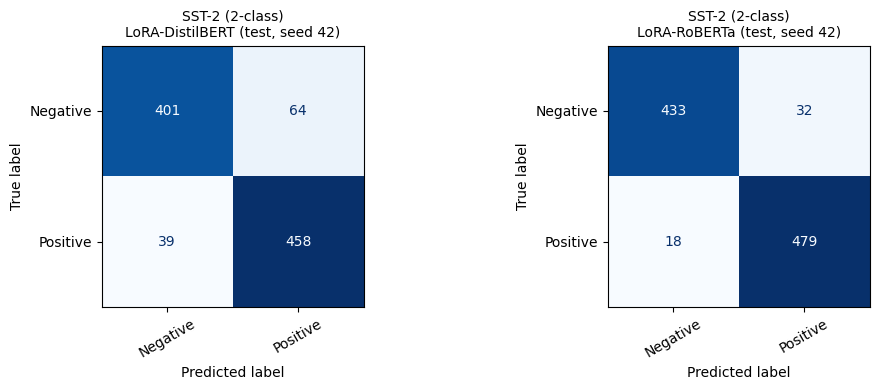

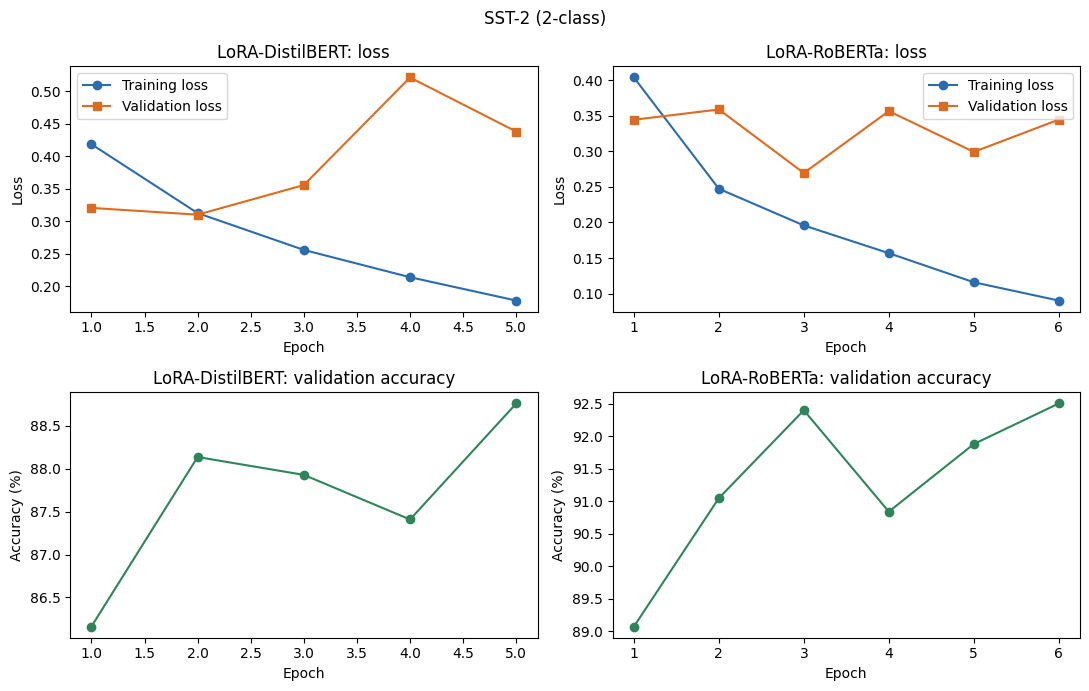

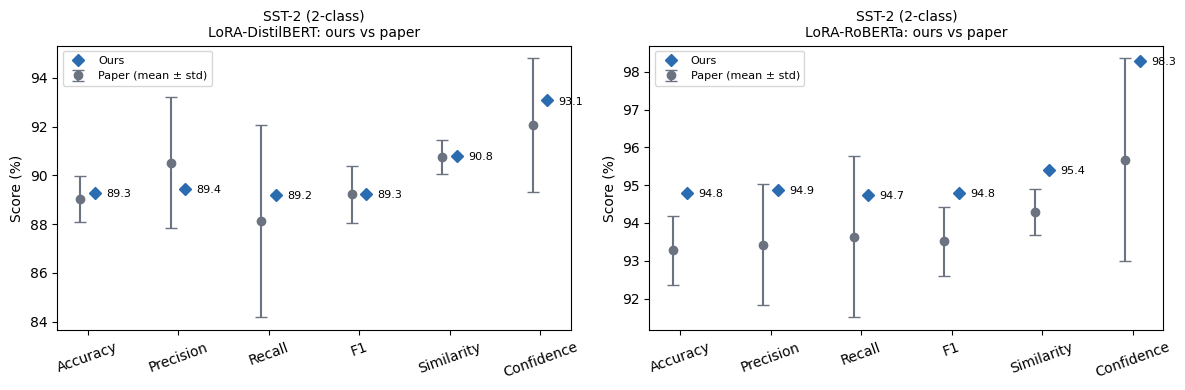


######## CARER Emotion (6-class) | rows 25000 (paper: 75000)
train/val/test: {'train': 20000, 'val': 2500, 'test': 2500}

===== emotion | LoRA-DistilBERT | seed 42 =====


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 742,662 || all params: 67,700,748 || trainable%: 1.0970


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.636022,0.265171,91.040000,89.088928,88.592823,88.774233,92.409760,91.967887,1.496860,0.134015
2,0.250396,0.198291,91.640000,89.135257,88.471703,88.611362,93.653695,93.596567,2.035795,0.109771
3,0.185805,0.172096,93.000000,90.797270,91.230543,90.894870,94.597241,94.072373,1.390938,0.093699
4,0.156169,0.160296,93.160000,91.481515,91.140430,91.258420,94.938847,94.651067,1.564800,0.087618
5,0.144890,0.160466,93.640000,91.471778,92.360810,91.880211,94.975457,94.579913,1.892597,0.087154


TEST -> acc 92.96 | F1 89.67 | 111s | 0.74 GB | trainable 742,662

CARER Emotion (6-class) | LoRA-DistilBERT | runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,93.22 ± 0.03,92.96,-0.26,no
1,Precision,89.85 ± 0.03,89.22,-0.63,no
2,Recall,90.60 ± 0.03,90.28,-0.32,no
3,F1,90.20 ± 0.03,89.67,-0.53,no
4,Similarity,92.45 ± 0.01,94.91,+2.46,no
5,Confidence,94.70 ± 0.03,94.86,+0.16,no
6,ECE,1.73 ± 0.12,1.92,+0.19,no
7,Brier,0.083 ± 0.000,0.088,+0.005,–
8,Trainable params,742.66K,"742,662",,
9,Training time (s),364,111,,


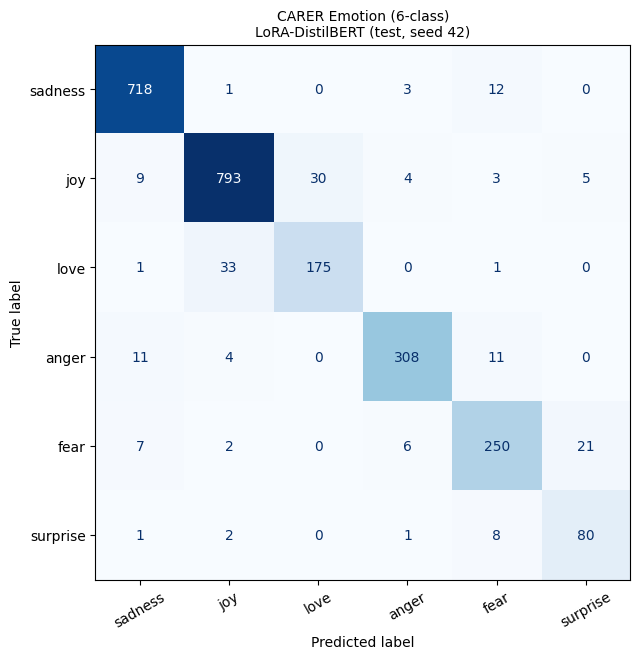

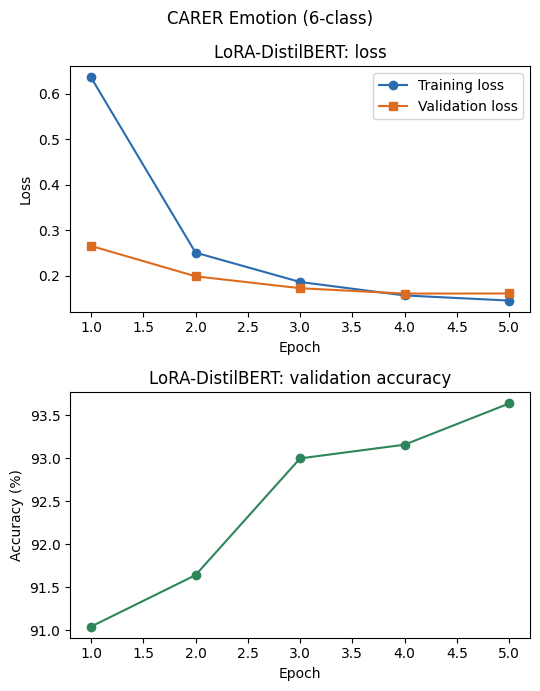

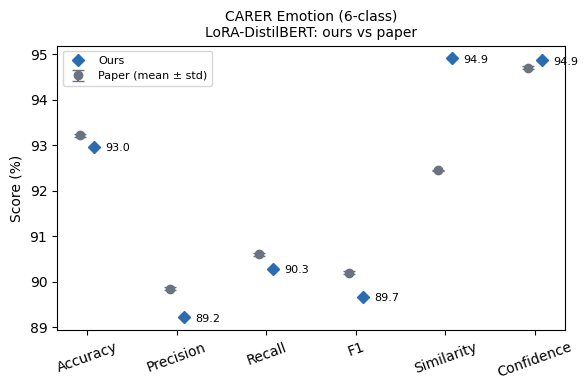


######## Amazon E-Commerce (5-class) | rows 22641 (paper: 22641)
train/val/test: {'train': 18112, 'val': 2264, 'test': 2265}

===== ecom5 | LoRA-mBERT | seed 42 =====


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 298,757 || all params: 167,659,018 || trainable%: 0.1782


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.990564,0.892189,62.367491,38.227662,31.454897,30.119629,70.356569,72.174228,9.806737,0.484069
2,0.826054,0.814641,65.680212,41.047108,45.165179,42.036869,72.680559,71.905057,6.560195,0.454449
3,0.758258,0.806673,65.901060,48.646337,44.076346,44.576896,72.829311,71.256897,5.774669,0.450321


TEST -> acc 67.42 | F1 48.38 | 368s | 1.22 GB | trainable 298,757

Amazon E-Commerce (5-class) | LoRA-mBERT | runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,67.63 ± 0.26,67.42,-0.21,yes
1,Precision,53.88 ± 2.34,54.04,+0.16,yes
2,Recall,46.05 ± 1.07,47.00,+0.95,yes
3,F1,47.37 ± 1.48,48.38,+1.01,yes
4,Similarity,74.06 ± 0.03,74.15,+0.09,no
5,Confidence,71.03 ± 0.37,70.79,-0.24,yes
6,ECE,3.67 ± 0.35,4.27,+0.60,no
7,Brier,0.430 ± 0.000,0.428,-0.002,–
8,Trainable params,298.76K,"298,757",,
9,Training time (s),413,368,,


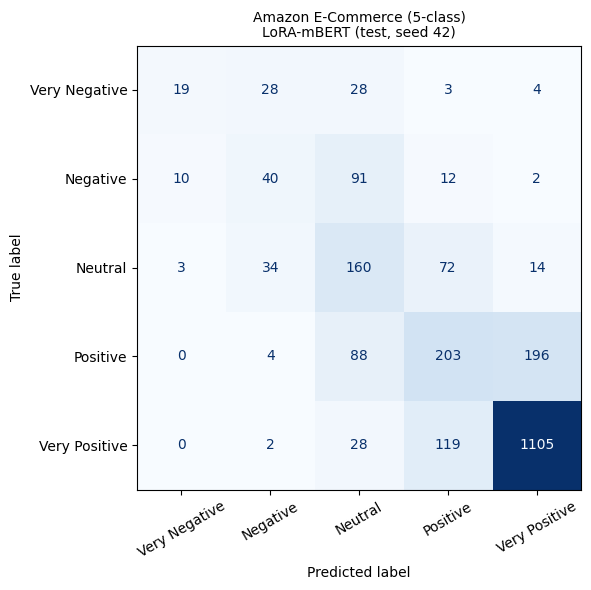

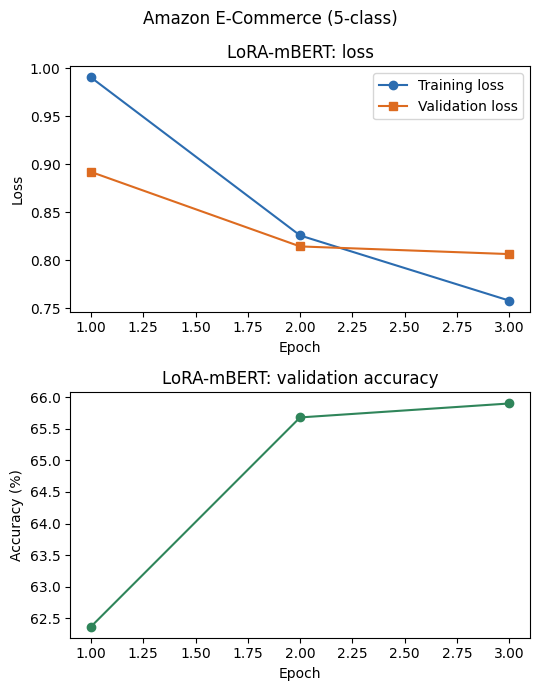

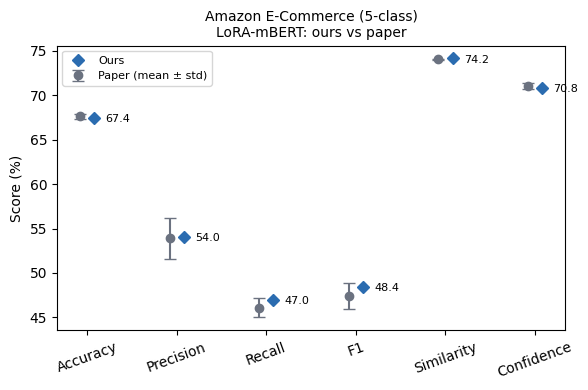


######## SemEval-2014 ABSA (Laptop+Restaurant, 3-class) | rows 5914 (paper: 5914)
train/val/test: {'train': 4731, 'val': 591, 'test': 592}

===== absa | LoRA-DeBERTa-v3 | seed 42 =====


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.den

trainable params: 334,083 || all params: 184,758,534 || trainable%: 0.1808


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.870857,0.673998,73.265651,69.183048,73.265651,70.059143,78.142943,79.817290,6.551638,0.375140
2,0.599080,0.695402,76.649746,74.562997,76.649746,75.076914,79.504289,85.595273,10.900306,0.365162
3,0.527113,0.708433,77.326565,75.722008,77.326565,75.914763,80.067636,88.163758,11.115613,0.361988
4,0.475655,0.613838,78.510998,78.096424,78.510998,78.138534,81.318938,86.441717,9.130952,0.335427
5,0.431125,0.695560,75.803723,74.703812,75.803723,74.740543,79.462466,90.086483,14.282761,0.370077
6,0.406147,0.687936,77.495770,76.359347,77.495770,76.659618,80.178427,91.159782,13.664012,0.360643
7,0.368807,0.745983,76.818951,75.703655,76.818951,76.029453,79.558687,91.940402,15.203482,0.376190


TEST -> acc 80.07 | F1 79.43 | 425s | 1.59 GB | trainable 334,083

SemEval-2014 ABSA (Laptop+Restaurant, 3-class) | LoRA-DeBERTa-v3 | runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,80.74 ± 0.00,80.07,-0.67,–
1,Precision,79.57 ± 0.00,80.21,+0.64,–
2,Recall,80.74 ± 0.00,80.07,-0.67,–
3,F1,79.84 ± 0.00,79.43,-0.41,–
4,Similarity,84.38 ± 0.00,82.56,-1.82,–
5,Confidence,83.92 ± 0.00,85.79,+1.87,–
6,ECE,4.34 ± 0.00,7.36,+3.02,–
7,Brier,0.270 ± 0.000,0.310,+0.040,–
8,Trainable params,334.08K,"334,083",,
9,Training time (s),2510,425,,


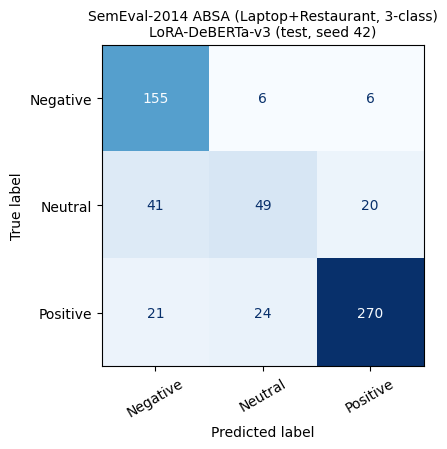

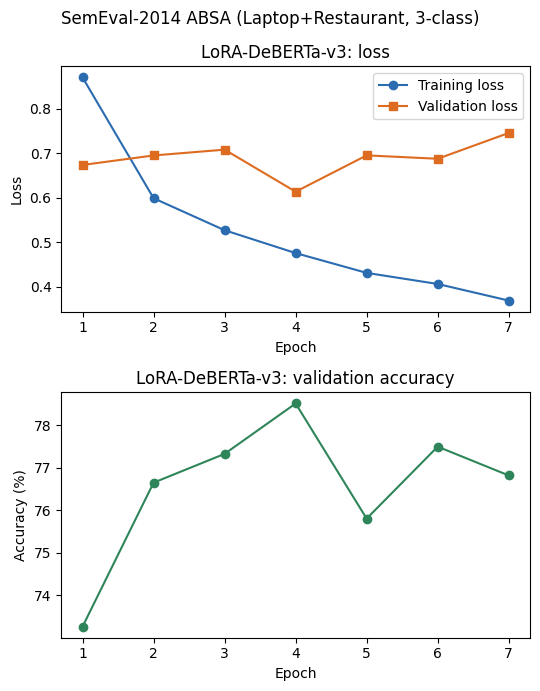

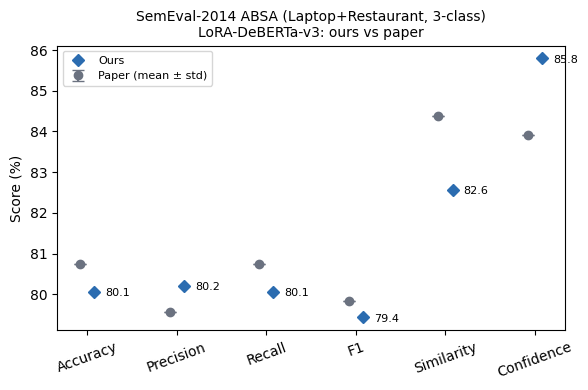

['emotion', 'ecom5', 'sst2', 'absa', 'all_results.csv']


In [16]:
import traceback
ALL = []
for ds in DATASETS:
    try:
        ALL.append(run_dataset(ds))
    except Exception:
        print(f"!!! {ds} failed, moving on to the next dataset"); traceback.print_exc()
if ALL:
    pd.concat(ALL).to_csv(f"{OUT}/all_results.csv", index=False)
print(os.listdir(OUT))